# 基于 BP 神经网络与 SVM 的男女生分类
## 模式识别第二次作业

本实验使用身高、体重、鞋码和 50 米成绩四个特征，比较手写反向传播的 **4–3–1 多层感知机（MLP）** 与四种核函数的支持向量机（SVM）。
女生编码为 0，男生编码为 1；两种方法使用完全相同的样本、外层五折和 SE、SP、ACC、AUC 定义。

实验流程为：**数据审计 → 固定实验协议 → 手写 BP 与梯度检查 → 嵌套五折评估 → 分方法及对比分析**。
外层五折评估泛化表现，内层五折仅使用外层训练集选择超参数；缺失值填补和标准化参数均由对应训练部分估计。
所有表格与图像在执行时生成，完整结果同时保存到 `results/homework2/`，Notebook 可从原始数据独立执行。

In [1]:
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = "1"

from pathlib import Path
from itertools import product
import hashlib
import json
import platform
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
import sklearn
import scipy
from scipy.special import expit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.manifold import TSNE

%matplotlib inline

DATA_PATH = Path("pattern_recognition_homework_dataset.xlsx")
OUT = Path("results/homework2")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 23
FEATURES = ["身高(cm)", "体重(kg)", "鞋码", "50米成绩"]
CLASS_NAMES = {0: "女生", 1: "男生"}
CLASS_COLORS = {0: "#A34D91", 1: "#167D9A"}
MODEL_NAMES = ["MLP-BP", "SVM-linear", "SVM-rbf", "SVM-poly", "SVM-sigmoid", "SVM-selected"]
MODEL_COLORS = dict(zip(MODEL_NAMES, ["#C36A2D", "#277DA8", "#468B58", "#8C61AA", "#B95869", "#263C54"]))
METRICS = ["SE", "SP", "ACC", "AUC"]
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
font_name = next((f for f in ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "Arial Unicode MS"] if f in available_fonts), "DejaVu Sans")
plt.rcParams.update({"font.family": font_name, "axes.unicode_minus": False, "figure.dpi": 115,
    "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.16, "axes.axisbelow": True,
    "svg.fonttype": "none"})
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 50)

def show_table(frame: pd.DataFrame, precision: int = 4) -> None:
    display(frame.style.format(precision=precision).hide(axis="index"))

def save_table(frame: pd.DataFrame, filename: str) -> None:
    frame.to_csv(OUT / filename, index=False, encoding="utf-8-sig")

def show_figure(figure, name: str) -> None:
    figure.savefig(FIG / f"{name}.png", dpi=250, bbox_inches="tight", facecolor="white")
    svg_path = FIG / f"{name}.svg"
    figure.savefig(svg_path, bbox_inches="tight", facecolor="white")
    svg_text = svg_path.read_text(encoding="utf-8")
    svg_path.write_text("\n".join(line.rstrip() for line in svg_text.splitlines()) + "\n", encoding="utf-8")
    plt.show()
    plt.close(figure)

print(f"Python {platform.python_version()}, NumPy {np.__version__}, scikit-learn {sklearn.__version__}; seed={SEED}")

Python 3.10.19, NumPy 2.2.6, scikit-learn 1.7.2; seed=23


### 1. 数据读取与质量检查

数据读取范围包括编号、标签和四个指定特征。编号用于重复记录核验，不作为预测特征。排除标签无法明确解释为 0 或 1 的记录，以及四个特征全部缺失的记录。

在训练前固定以下宽范围作为录入质量规则：身高 130–220 cm、体重 30–200 kg、鞋码 30–50、50 米成绩 5–20 s（均含端点）。这些范围不依赖性别和分类结果，范围外或无法解析的输入置为缺失，不推断其原始取值。范围内的罕见值予以保留；不同编号且特征相同的记录按不同样本处理。

对于其余缺失值，**在每个训练折计算四列中位数**，填补训练与验证/测试数据；再用训练折均值与标准差进行标准化：
$$z_{ij}=\frac{\widetilde{x}_{ij}-\mu_j^{\mathrm{train}}}{s_j^{\mathrm{train}}}.$$
因此，首次作业中按全体类别计算的离群点筛选不用于本次交叉验证。

项目,数量
raw_n,1280
invalid_label_n,5
valid_label_all_features_missing_n,1
retained_n,1274
female_n,256
male_n,1018
retained_any_missing_n,20
duplicate_identifier_n,0
repeated_feature_label_rows_n,35


feature,lower,upper,original_missing,non_numeric,outside_range,retained_missing
身高(cm),130,220,1,0,1,1
体重(kg),30,200,2,0,0,1
鞋码,30,50,3,0,1,3
50米成绩,5,20,14,4,0,17


保留 **1274** 条记录：女生 **256**，男生 **1018**；男生占比 **79.91%**。

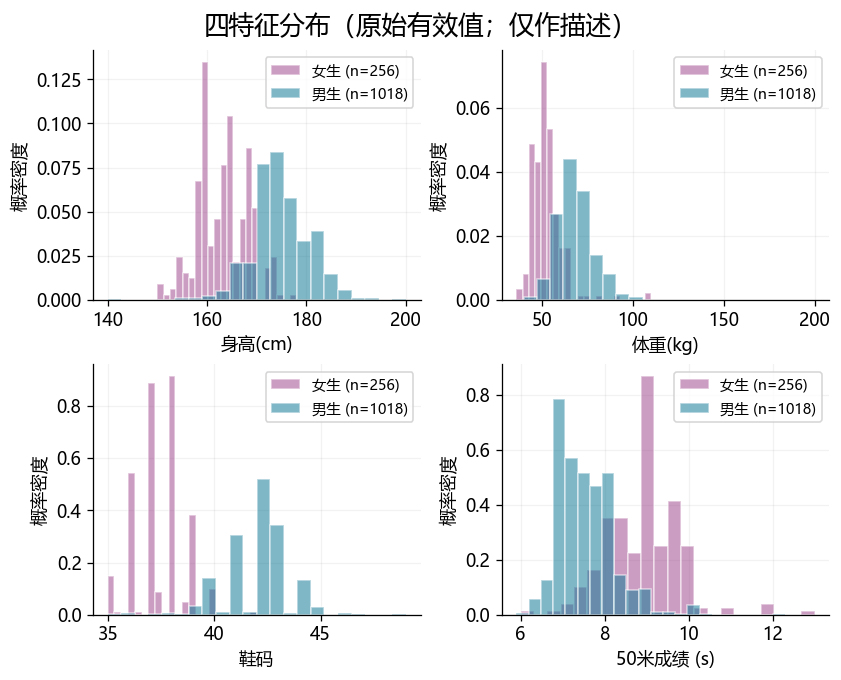

In [2]:
raw = pd.read_excel(DATA_PATH, usecols=["编号", "性别 男1女0", *FEATURES])
assert raw["编号"].notna().all() and raw["编号"].is_unique, "重复编号必须先采用分组划分，不能直接运行样本级CV。"
labels = pd.to_numeric(raw["性别 男1女0"], errors="coerce")
valid_label = labels.isin([0, 1])
quality_bounds = {"身高(cm)": [130, 220], "体重(kg)": [30, 200], "鞋码": [30, 50], "50米成绩": [5, 20]}
numeric = raw[FEATURES].apply(pd.to_numeric, errors="coerce")
quality_rows = []
for feature, (lower, upper) in quality_bounds.items():
    outside = numeric[feature].notna() & ~numeric[feature].between(lower, upper)
    quality_rows.append({"feature": feature, "lower": lower, "upper": upper,
        "original_missing": int(raw[feature].isna().sum()),
        "non_numeric": int((raw[feature].notna() & numeric[feature].isna()).sum()),
        "outside_range": int(outside.sum())})
    numeric.loc[outside, feature] = np.nan
all_missing = numeric.isna().all(axis=1)
keep = valid_label & ~all_missing
clean = numeric.loc[keep].copy().reset_index(drop=True)
clean.insert(0, "row_id", [f"row_{i+1:04d}" for i in raw.index[keep]])
clean["label"] = labels.loc[keep].astype(int).to_numpy()
X = clean[FEATURES].to_numpy(float)
y = clean["label"].to_numpy(int)
quality = pd.DataFrame(quality_rows)
quality["retained_missing"] = clean[FEATURES].isna().sum().to_numpy()
data_audit = {"raw_n": len(raw), "invalid_label_n": int((~valid_label).sum()),
    "valid_label_all_features_missing_n": int((valid_label & all_missing).sum()),
    "retained_n": len(clean), "female_n": int((y == 0).sum()), "male_n": int((y == 1).sum()),
    "retained_any_missing_n": int(np.isnan(X).any(axis=1).sum()),
    "duplicate_identifier_n": int(raw["编号"].duplicated().sum()),
    "repeated_feature_label_rows_n": int(clean.duplicated(subset=[*FEATURES, "label"]).sum())}
show_table(pd.DataFrame({"项目": list(data_audit), "数量": list(data_audit.values())}), 0)
show_table(quality, 0)
save_table(quality, "data_quality.csv")
feature_summary = clean.groupby("label")[FEATURES].agg(["count", "mean", "std", "min", "median", "max"])
feature_summary.columns = [f"{a}_{b}" for a, b in feature_summary.columns]
save_table(feature_summary.reset_index(), "feature_summary.csv")
(OUT / "data_audit.json").write_text(json.dumps(data_audit, ensure_ascii=False, indent=2), encoding="utf-8")
display(Markdown(f"保留 **{len(clean)}** 条记录：女生 **{(y==0).sum()}**，男生 **{(y==1).sum()}**；男生占比 **{(y==1).mean():.2%}**。"))

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.8), layout="constrained")
for j, ax in enumerate(axes.flat):
    for label in [0, 1]:
        values = X[y == label, j]
        ax.hist(values[np.isfinite(values)], bins=22, density=True, alpha=0.55,
                label=f"{CLASS_NAMES[label]} (n={(y==label).sum()})", color=CLASS_COLORS[label], edgecolor="white")
    ax.set(xlabel=FEATURES[j] + (" (s)" if j == 3 else ""), ylabel="概率密度")
    ax.legend(fontsize=9)
fig.suptitle("四特征分布（原始有效值；仅作描述）", fontsize=16)
show_figure(fig, "feature_distributions")

### 2. 固定评估协议与统一指标

分层外层五折保证每个样本仅参与一次外层测试。每个外层训练集再做分层内层五折，按**内层平均 AUC 最大**选择参数，随后在整个外层训练集重训。两种方法共享外层划分、内层划分和预处理规则。MLP 测试阈值固定为 0.5；SVM 使用决策函数 0 阈值，不在测试集调整。

将男生设为正类，$TP$ 为正确识别的男生样本数，$TN$ 为正确识别的女生样本数，$FN$ 为男生误判为女生的样本数，$FP$ 为女生误判为男生的样本数：
$$\mathrm{SE}=\frac{TP}{TP+FN},\quad \mathrm{SP}=\frac{TN}{TN+FP},\quad
\mathrm{ACC}=\frac{TP+TN}{TP+TN+FP+FN}.$$
AUC 用 `roc_auc_score` 计算：MLP 使用男生概率，SVM 使用有符号决策分数。AUC 衡量排序，与固定阈值的分类指标含义不同。

主结果为五个外层折指标的**算术均值 ± 样本标准差（ddof=1）**。混淆矩阵汇总所有折外预测（OOF），是按样本加权的计数；因此由汇总矩阵反算的比例与逐折平均可能略有差别。AUC 按折计算后汇总，不合并不同折的 SVM 决策分数。

SVM 的四种核分别进行超参数选择与结果汇总。另定义 **SVM-selected**：在每个外层训练集的内层五折中，同时选择核和参数；该选择流程与 MLP 进行主比较，核函数选择限定在内层训练流程内。搜索网格、随机种子与数据摘要在正式拟合前写入 `protocol.json`。

In [3]:
MLP_GRID = [{"alpha": a, "learning_rate": lr} for a, lr in product([0.0, 0.001, 0.01], [0.01, 0.03])]
SVM_GRIDS = {
    "linear": [{"kernel": "linear", "C": c} for c in [0.1, 1.0, 10.0]],
    "rbf": [{"kernel": "rbf", "C": c, "gamma": g} for c, g in product([0.1, 1.0, 10.0], [0.1, 0.25, 1.0])],
    "poly": [{"kernel": "poly", "C": c, "gamma": g, "degree": 3, "coef0": 1.0}
             for c, g in product([0.1, 1.0, 10.0], [0.1, 0.25, 1.0])],
    "sigmoid": [{"kernel": "sigmoid", "C": c, "gamma": g, "coef0": 0.0}
                for c, g in product([0.1, 1.0, 10.0], [0.1, 0.25, 1.0])],
}
EPOCHS = 800
outer_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y))
fold_rows = []
fold_for_sample = np.zeros(len(y), dtype=int)
for fold, (train_index, test_index) in enumerate(outer_splits, 1):
    assert set(train_index).isdisjoint(test_index)
    fold_for_sample[test_index] = fold
    fold_rows.append({"fold": fold, "train_n": len(train_index), "train_female": int((y[train_index]==0).sum()),
        "train_male": int((y[train_index]==1).sum()), "test_n": len(test_index),
        "test_female": int((y[test_index]==0).sum()), "test_male": int((y[test_index]==1).sum())})
assert np.all(fold_for_sample > 0)
protocol = {"assignment": 2, "seed": SEED, "features": FEATURES, "positive_class": 1,
    "outer_folds": 5, "inner_folds": 5, "splitter": "StratifiedKFold(shuffle=True)",
    "inner_seed": "SEED + outer_fold", "model_seed": "SEED + 100 * outer_fold + inner_fold (outer refit: inner_fold=0)",
    "quality_bounds": quality_bounds, "drop": "invalid label or all four features missing",
    "missing": "training-partition median", "scaling": "training-partition StandardScaler(ddof=0)",
    "selection_metric": "mean inner-fold ROC AUC", "tie_break": "first candidate in fixed grid",
    "report": "mean and sample SD (ddof=1) over outer folds", "thresholds": {"MLP-BP": 0.5, "SVM": 0.0},
    "MLP": {"architecture": [4,3,1], "hidden": "tanh", "output": "sigmoid", "loss": "mean BCE + alpha/2 * sum(weight squared)",
        "optimizer": "manual full-batch Adam", "epochs": EPOCHS, "grid": MLP_GRID, "beta1": 0.9, "beta2": 0.999, "epsilon": 1e-8},
    "SVM": {"grids": SVM_GRIDS, "class_weight": None, "probability": False, "tol": 0.001, "max_iter": -1},
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(), "data_audit": data_audit,
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}}
(OUT / "protocol.json").write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding="utf-8")
fold_counts = pd.DataFrame(fold_rows)
save_table(fold_counts, "fold_counts.csv")
save_table(pd.DataFrame({"row_id": clean["row_id"], "label": y, "fold": fold_for_sample}), "fold_assignments.csv")
show_table(fold_counts, 0)
show_table(pd.DataFrame(MLP_GRID))
print("正式协议已保存；MLP候选6组，SVM候选共", sum(map(len, SVM_GRIDS.values())), "组。")

fold,train_n,train_female,train_male,test_n,test_female,test_male
1,1019,205,814,255,51,204
2,1019,205,814,255,51,204
3,1019,205,814,255,51,204
4,1019,204,815,255,52,203
5,1020,205,815,254,51,203


alpha,learning_rate
0.0000,0.0100
0.0000,0.0300
0.0010,0.0100
0.0010,0.0300
0.0100,0.0100
0.0100,0.0300


正式协议已保存；MLP候选6组，SVM候选共 30 组。


### 3. BP 神经网络：前向传播、损失与手写梯度

网络设置一个含 3 个节点的隐层，四维输入经标准化后送入网络：
$$H=\tanh(XW_1+b_1),\qquad a=HW_2+b_2,\qquad p=\sigma(a)=\frac{1}{1+e^{-a}}.$$
其中 $W_1\in\mathbb R^{4\times3}$、$b_1\in\mathbb R^3$、$W_2\in\mathbb R^{3\times1}$、$b_2\in\mathbb R$，共有 **19 个可训练参数**。优化目标为平均二元交叉熵加权重 L2 正则项：
$$L=\frac1n\sum_i[\log(1+e^{a_i})-y_i a_i]+\frac\lambda2(\|W_1\|_F^2+\|W_2\|_F^2).$$
数值实现用 `logaddexp(0,a)` 防止指数溢出。偏置不参与正则化。反向传播直接由链式法则计算：
$$\Delta_2=\frac{p-y}{n},\quad \Delta_1=(\Delta_2W_2^T)\odot(1-H^2),$$
$$\nabla_{W_2}L=H^T\Delta_2+\lambda W_2,\quad \nabla_{b_2}L=\sum_i\Delta_{2,i},$$
$$\nabla_{W_1}L=X^T\Delta_1+\lambda W_1,\quad \nabla_{b_1}L=\sum_i\Delta_{1,i}.$$

权重采用 Glorot 均匀初始化，偏置初始化为零；每轮对全部训练样本做一次梯度计算，手写 Adam 的一、二阶矩和偏差修正后更新参数。固定训练 800 轮，测试集不参与停止时机选择。不调用平台神经网络分类器、自动微分或优化器。

In [4]:
class ManualMLP:
    """Exactly one 3-node hidden layer; NumPy BP and Adam, no autograd."""
    def __init__(self, alpha: float = 0.001, learning_rate: float = 0.01,
                 epochs: int = EPOCHS, random_state: int = SEED):
        self.alpha, self.learning_rate = alpha, learning_rate
        self.epochs, self.random_state = epochs, random_state

    def initialize(self, n_features: int = 4) -> None:
        rng = np.random.default_rng(self.random_state)
        limit1, limit2 = np.sqrt(6 / (n_features + 3)), np.sqrt(6 / (3 + 1))
        self.params = {"W1": rng.uniform(-limit1, limit1, (n_features, 3)), "b1": np.zeros(3),
                       "W2": rng.uniform(-limit2, limit2, (3, 1)), "b2": np.zeros(1)}

    def forward(self, inputs: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        p = self.params
        hidden = np.tanh(inputs @ p["W1"] + p["b1"])
        logits = (hidden @ p["W2"] + p["b2"]).ravel()
        return hidden, logits, expit(logits)

    def loss_and_gradients(self, inputs: np.ndarray, targets: np.ndarray) -> tuple[float, dict]:
        hidden, logits, probabilities = self.forward(inputs)
        p = self.params
        penalty = self.alpha / 2 * (np.sum(p["W1"]**2) + np.sum(p["W2"]**2))
        loss = np.mean(np.logaddexp(0, logits) - targets * logits) + penalty
        delta2 = ((probabilities - targets) / len(targets))[:, None]
        delta1 = (delta2 @ p["W2"].T) * (1 - hidden**2)
        gradients = {"W1": inputs.T @ delta1 + self.alpha * p["W1"], "b1": delta1.sum(axis=0),
                     "W2": hidden.T @ delta2 + self.alpha * p["W2"], "b2": delta2.sum(axis=0)}
        return float(loss), gradients

    def fit(self, inputs: np.ndarray, targets: np.ndarray):
        inputs, targets = np.asarray(inputs, float), np.asarray(targets, float)
        assert inputs.ndim == 2 and inputs.shape[1] == 4
        assert np.isfinite(inputs).all() and set(np.unique(targets)) <= {0, 1}
        self.initialize(inputs.shape[1])
        first = {k: np.zeros_like(v) for k, v in self.params.items()}
        second = {k: np.zeros_like(v) for k, v in self.params.items()}
        self.history = []
        for step in range(1, self.epochs + 1):
            loss, gradients = self.loss_and_gradients(inputs, targets)
            if step == 1 or step % 20 == 0:
                self.history.append({"epoch": step - 1, "loss": loss})
            for key, gradient in gradients.items():
                first[key] = 0.9 * first[key] + 0.1 * gradient
                second[key] = 0.999 * second[key] + 0.001 * gradient**2
                corrected_first = first[key] / (1 - 0.9**step)
                corrected_second = second[key] / (1 - 0.999**step)
                self.params[key] -= self.learning_rate * corrected_first / (np.sqrt(corrected_second) + 1e-8)
        final_loss, _ = self.loss_and_gradients(inputs, targets)
        self.history.append({"epoch": self.epochs, "loss": final_loss})
        assert np.isfinite(final_loss), "训练出现非有限损失。"
        return self

    def predict_score(self, inputs: np.ndarray) -> np.ndarray:
        return self.forward(np.asarray(inputs, float))[2]

    def predict(self, inputs: np.ndarray) -> np.ndarray:
        return (self.predict_score(inputs) >= 0.5).astype(int)


# 中心差分检查所有19个参数，同时覆盖不为零的L2梯度。
check_rng = np.random.default_rng(2026)
check_X = check_rng.normal(size=(7, 4))
check_y = np.array([0, 1, 0, 1, 1, 0, 1], dtype=float)
check_model = ManualMLP(alpha=0.01, random_state=11)
check_model.initialize()
_, analytic = check_model.loss_and_gradients(check_X, check_y)
gradient_rows = []
epsilon = 1e-5
for key, array in check_model.params.items():
    for index in np.ndindex(array.shape):
        original = float(array[index])
        array[index] = original + epsilon
        plus, _ = check_model.loss_and_gradients(check_X, check_y)
        array[index] = original - epsilon
        minus, _ = check_model.loss_and_gradients(check_X, check_y)
        array[index] = original
        numerical = (plus - minus) / (2 * epsilon)
        exact = float(analytic[key][index])
        gradient_rows.append({"parameter": f"{key}{index}", "analytic": exact, "numerical": numerical,
            "absolute_error": abs(exact-numerical), "relative_error": abs(exact-numerical)/max(1e-8, abs(exact)+abs(numerical))})
gradient_check = pd.DataFrame(gradient_rows)
assert len(gradient_check) == 19 and gradient_check["absolute_error"].max() < 1e-7
assert gradient_check["relative_error"].max() < 1e-5
assert np.isfinite(expit(np.array([-1000.0, 1000.0]))).all()
save_table(gradient_check, "gradient_check.csv")
show_table(gradient_check, 10)
print("梯度检查通过：最大绝对误差", gradient_check["absolute_error"].max())

parameter,analytic,numerical,absolute_error,relative_error
"W1(0, 0)",-0.0386282686,-0.0386282686,0.0000000000,0.0000000000
"W1(0, 1)",0.0607988712,0.0607988712,0.0000000000,0.0000000001
"W1(0, 2)",0.0759527059,0.0759527058,0.0000000000,0.0000000000
"W1(1, 0)",-0.0242884496,-0.0242884496,0.0000000000,0.0000000000
"W1(1, 1)",0.0194655642,0.0194655642,0.0000000000,0.0000000002
"W1(1, 2)",0.0594530507,0.0594530507,0.0000000000,0.0000000001
"W1(2, 0)",0.0165759844,0.0165759844,0.0000000000,0.0000000001
"W1(2, 1)",0.0134187547,0.0134187548,0.0000000000,0.0000000005
"W1(2, 2)",-0.0243945760,-0.0243945760,0.0000000000,0.0000000001
"W1(3, 0)",0.0492602451,0.0492602451,0.0000000000,0.0000000000


梯度检查通过：最大绝对误差 1.717392200673018e-11


### 4. SVM 与四种核函数

将标签转换为 $t_i\in\{-1,+1\}$，软间隔 SVM 求解：
$$\min_{w,b,\xi}\frac12\|w\|^2+C\sum_i\xi_i,\qquad
t_i(w^T\phi(x_i)+b)\ge1-\xi_i,\quad\xi_i\ge0.$$
预测分数为 $f(x)=\sum_i\alpha_i t_i K(x_i,x)+b$。使用 scikit-learn `SVC` 完成训练，参数 $C$ 控制对训练错误的惩罚。四种核为：

| 核函数 | 定义 | 本实验搜索范围 |
|:---|:---|:---|
| Linear | $K(x,z)=x^Tz$ | $C\in\{0.1,1,10\}$ |
| RBF | $K(x,z)=\exp[-\gamma\|x-z\|^2]$ | 上述 $C$；$\gamma\in\{0.1,0.25,1\}$ |
| Polynomial | $K(x,z)=(\gamma x^Tz+r)^d$ | 上述 $C,\gamma$；$d=3,r=1$ |
| Sigmoid | $K(x,z)=\tanh(\gamma x^Tz+r)$ | 上述 $C,\gamma$；$r=0$ |

全部使用相同的标准化输入和原始类别比例，`class_weight=None`。关闭概率标定，直接使用决策函数计算 AUC；SVM 分数不解释为概率。Sigmoid 形式并非对任意参数和输入都满足正半定条件，其结果作为该具体设置下的经验比较。

In [5]:
def make_preprocessor():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

def evaluate(targets: np.ndarray, predictions: np.ndarray, scores: np.ndarray) -> dict:
    tn, fp, fn, tp = confusion_matrix(targets, predictions, labels=[0, 1]).ravel()
    return {"SE": tp/(tp+fn), "SP": tn/(tn+fp), "ACC": (tp+tn)/len(targets),
            "AUC": roc_auc_score(targets, scores), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

def fit_svm(parameters: dict, inputs: np.ndarray, targets: np.ndarray):
    return SVC(**parameters, class_weight=None, probability=False, tol=0.001,
               max_iter=-1, cache_size=256, random_state=SEED).fit(inputs, targets)

def choose_candidate(candidates: list[dict], inner_data: list, family: str, fold: int) -> tuple[dict, float]:
    rows = []
    for candidate_index, parameters in enumerate(candidates):
        values = []
        for inner_fold, (inner_X, inner_y, valid_X, valid_y) in enumerate(inner_data, 1):
            if family == "MLP-BP":
                estimator = ManualMLP(**parameters, random_state=SEED+100*fold+inner_fold).fit(inner_X, inner_y)
                scores = estimator.predict_score(valid_X)
            else:
                estimator = fit_svm(parameters, inner_X, inner_y)
                scores = estimator.decision_function(valid_X)
            values.append(roc_auc_score(valid_y, scores))
        row = {"outer_fold": fold, "family": family, "candidate": candidate_index,
            "parameters": json.dumps(parameters, sort_keys=True), "inner_AUC_mean": float(np.mean(values)),
            "inner_AUC_sd": float(np.std(values, ddof=1))}
        row.update({f"inner_{j+1}_AUC": value for j, value in enumerate(values)})
        rows.append(row)
    search_rows.extend(rows)
    best = int(np.argmax([row["inner_AUC_mean"] for row in rows]))
    return dict(candidates[best]), rows[best]["inner_AUC_mean"]

search_rows, result_rows, train_rows, prediction_rows, selection_rows, history_rows = [], [], [], [], [], []
outer_models = {}
begin = time.perf_counter()
for fold, (train_index, test_index) in enumerate(outer_splits, 1):
    train_X, test_X, train_y, test_y = X[train_index], X[test_index], y[train_index], y[test_index]
    inner_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED+fold).split(train_X, train_y))
    inner_data = []
    for fit_index, valid_index in inner_splits:
        preprocessor = make_preprocessor()
        inner_data.append((preprocessor.fit_transform(train_X[fit_index]), train_y[fit_index],
                           preprocessor.transform(train_X[valid_index]), train_y[valid_index]))
    mlp_parameters, mlp_inner_auc = choose_candidate(MLP_GRID, inner_data, "MLP-BP", fold)
    kernel_best = {kernel: choose_candidate(grid, inner_data, f"SVM-{kernel}", fold)
                   for kernel, grid in SVM_GRIDS.items()}
    selected_kernel = max(kernel_best, key=lambda k: kernel_best[k][1])
    preprocessor = make_preprocessor()
    transformed_train = preprocessor.fit_transform(train_X)
    transformed_test = preprocessor.transform(test_X)
    models = {"MLP-BP": ManualMLP(**mlp_parameters, random_state=SEED+100*fold).fit(transformed_train, train_y)}
    parameters_by_model = {"MLP-BP": (mlp_parameters, mlp_inner_auc)}
    for kernel, (parameters, auc) in kernel_best.items():
        models[f"SVM-{kernel}"] = fit_svm(parameters, transformed_train, train_y)
        parameters_by_model[f"SVM-{kernel}"] = (parameters, auc)
    models["SVM-selected"] = models[f"SVM-{selected_kernel}"]
    parameters_by_model["SVM-selected"] = kernel_best[selected_kernel]
    for row in models["MLP-BP"].history:
        history_rows.append({"fold": fold, **row})
    for name, estimator in models.items():
        if name == "MLP-BP":
            scores, train_scores = estimator.predict_score(transformed_test), estimator.predict_score(transformed_train)
            predictions, train_predictions = (scores >= 0.5).astype(int), (train_scores >= 0.5).astype(int)
        else:
            scores, train_scores = estimator.decision_function(transformed_test), estimator.decision_function(transformed_train)
            predictions, train_predictions = (scores >= 0.0).astype(int), (train_scores >= 0.0).astype(int)
            assert np.array_equal(predictions, estimator.predict(transformed_test))
        result_rows.append({"model": name, "fold": fold, "n": len(test_y), **evaluate(test_y, predictions, scores)})
        train_rows.append({"model": name, "fold": fold, "n": len(train_y), **evaluate(train_y, train_predictions, train_scores)})
        for i, predicted, score in zip(test_index, predictions, scores):
            prediction_rows.append({"row_id": clean.iloc[i]["row_id"], "fold": fold, "model": name,
                "label": int(y[i]), "prediction": int(predicted), "score": float(score), "error": int(predicted != y[i])})
        chosen, inner_auc = parameters_by_model[name]
        selection_rows.append({"model": name, "fold": fold, "parameters": json.dumps(chosen, sort_keys=True),
            "inner_AUC": inner_auc, "support_vectors": int(estimator.n_support_.sum()) if name != "MLP-BP" else None,
            "support_fraction": float(estimator.n_support_.sum()/len(train_y)) if name != "MLP-BP" else None})
    outer_models[fold] = {"preprocessor": preprocessor, "models": models}
    print(f"外层 {fold}/5 完成；MLP={mlp_parameters}；SVM内层选择={selected_kernel}；累计 {time.perf_counter()-begin:.1f}s")

fold_metrics = pd.DataFrame(result_rows)
train_metrics = pd.DataFrame(train_rows)
oof = pd.DataFrame(prediction_rows)
selection = pd.DataFrame(selection_rows)
search = pd.DataFrame(search_rows)
loss_history = pd.DataFrame(history_rows)
for name in MODEL_NAMES:
    subset = oof[oof.model.eq(name)]
    assert len(subset) == len(y) and subset.row_id.is_unique
    assert np.isfinite(subset.score).all()
    assert sorted(subset.row_id) == sorted(clean.row_id)
summary_rows = []
for name in MODEL_NAMES:
    subset = fold_metrics[fold_metrics.model.eq(name)]
    row = {"model": name}
    for metric in METRICS:
        row[f"{metric}_mean"] = subset[metric].mean()
        row[f"{metric}_sd"] = subset[metric].std(ddof=1)
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
for frame, filename in [(fold_metrics,"fold_metrics.csv"), (train_metrics,"train_metrics.csv"),
                        (oof,"oof_predictions.csv"), (selection,"selected_parameters.csv"),
                        (search,"inner_search.csv"), (loss_history,"mlp_loss_history.csv"), (summary,"metrics_summary.csv")]:
    save_table(frame, filename)
print(f"正式嵌套交叉验证完成，总耗时 {time.perf_counter()-begin:.1f} s。")
show_table(fold_metrics)

外层 1/5 完成；MLP={'alpha': 0.0, 'learning_rate': 0.01}；SVM内层选择=rbf；累计 3.6s


外层 2/5 完成；MLP={'alpha': 0.01, 'learning_rate': 0.03}；SVM内层选择=rbf；累计 7.4s


外层 3/5 完成；MLP={'alpha': 0.01, 'learning_rate': 0.01}；SVM内层选择=rbf；累计 11.2s


外层 4/5 完成；MLP={'alpha': 0.001, 'learning_rate': 0.01}；SVM内层选择=rbf；累计 14.9s


外层 5/5 完成；MLP={'alpha': 0.001, 'learning_rate': 0.01}；SVM内层选择=rbf；累计 18.4s
正式嵌套交叉验证完成，总耗时 18.4 s。


model,fold,n,SE,SP,ACC,AUC,TN,FP,FN,TP
MLP-BP,1,255,0.9804,0.9216,0.9686,0.9859,47,4,4,200
SVM-linear,1,255,0.9804,0.9216,0.9686,0.9865,47,4,4,200
SVM-rbf,1,255,0.9804,0.9020,0.9647,0.9848,46,5,4,200
SVM-poly,1,255,0.9804,0.9020,0.9647,0.9858,46,5,4,200
SVM-sigmoid,1,255,0.9804,0.8627,0.9569,0.9868,44,7,4,200
SVM-selected,1,255,0.9804,0.9020,0.9647,0.9848,46,5,4,200
MLP-BP,2,255,0.9853,0.9804,0.9843,0.9950,50,1,3,201
SVM-linear,2,255,0.9853,0.9804,0.9843,0.9952,50,1,3,201
SVM-rbf,2,255,0.9853,0.9412,0.9765,0.9946,48,3,3,201
SVM-poly,2,255,0.9804,0.9804,0.9804,0.9953,50,1,4,200


### 5. MLP 结果：收敛、分类错误与排序能力

损失曲线记录五个外层最终模型的**训练集目标值**，用于分析优化过程的收敛性；外层测试集不参与训练监控或超参数调整。各折可能选取不同的正则化系数，因此不同折的损失绝对值不直接用于性能比较。

fold,parameters,inner_AUC
1,"{""alpha"": 0.0, ""learning_rate"": 0.01}",0.9922
2,"{""alpha"": 0.01, ""learning_rate"": 0.03}",0.9888
3,"{""alpha"": 0.01, ""learning_rate"": 0.01}",0.9907
4,"{""alpha"": 0.001, ""learning_rate"": 0.01}",0.9916
5,"{""alpha"": 0.001, ""learning_rate"": 0.01}",0.9892


model,fold,n,SE,SP,ACC,AUC,TN,FP,FN,TP
MLP-BP,1,255,0.9804,0.9216,0.9686,0.9859,47,4,4,200
MLP-BP,2,255,0.9853,0.9804,0.9843,0.9950,50,1,3,201
MLP-BP,3,255,0.9853,0.9412,0.9765,0.9904,48,3,3,201
MLP-BP,4,255,0.9803,0.9423,0.9725,0.9865,49,3,4,199
MLP-BP,5,254,0.9901,0.9412,0.9803,0.9920,48,3,2,201


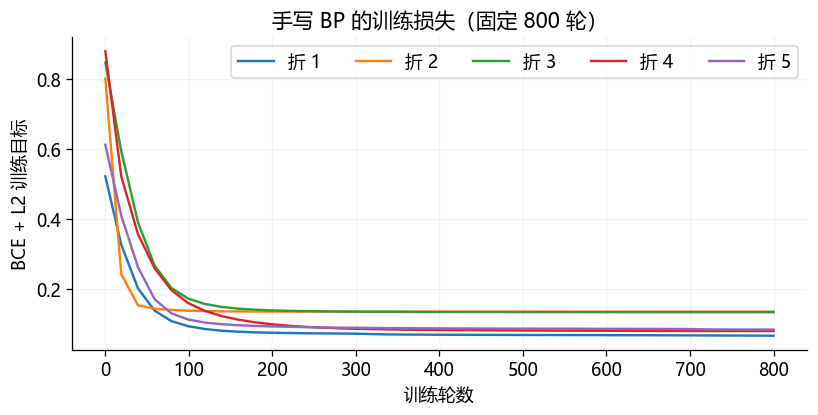

外层五折测试结果表明，MLP 的 ACC 为 **97.65% ± 0.62%**，AUC 为 **0.9900 ± 0.0038**。男生灵敏度为 98.43%，女生特异度为 94.53%；其中，14 名女生被判为男生，16 名男生被判为女生。训练 AUC 均值为 0.9919，与测试 AUC 的差距为 0.0020。由于男生样本占比较高，ACC 对女生误判的反映相对有限；结合 SE 与 SP 可进一步刻画两类样本的识别差异。

In [6]:
show_table(selection[selection.model.eq("MLP-BP")][["fold", "parameters", "inner_AUC"]])
show_table(fold_metrics[fold_metrics.model.eq("MLP-BP")])
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
for fold, group in loss_history.groupby("fold"):
    ax.plot(group.epoch, group.loss, label=f"折 {fold}")
ax.set(xlabel="训练轮数", ylabel="BCE + L2 训练目标", title="手写 BP 的训练损失（固定 800 轮）")
ax.legend(ncol=5)
show_figure(fig, "mlp_training_loss")

def cm_for(name: str) -> np.ndarray:
    group = oof[oof.model.eq(name)]
    return confusion_matrix(group.label, group.prediction, labels=[0,1])

def draw_cm(ax, name: str) -> None:
    counts = cm_for(name)
    rates = counts/counts.sum(axis=1, keepdims=True)
    ax.imshow(rates, cmap="Blues", vmin=0, vmax=1)
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f"{counts[row,col]}\n{rates[row,col]:.1%}", ha="center", va="center",
                    fontsize=14, color="white" if rates[row,col]>.55 else "#203345")
    ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["女生","男生"], yticklabels=["女生","男生"],
           xlabel="预测类别", ylabel="真实类别", title=name)
    ax.grid(False)

mlp_summary = summary.set_index("model").loc["MLP-BP"]
mlp_cm = cm_for("MLP-BP")
mlp_train_auc = train_metrics[train_metrics.model.eq("MLP-BP")].AUC.mean()
display(Markdown(f"外层五折测试结果表明，MLP 的 ACC 为 **{mlp_summary.ACC_mean:.2%} ± {mlp_summary.ACC_sd:.2%}**，AUC 为 **{mlp_summary.AUC_mean:.4f} ± {mlp_summary.AUC_sd:.4f}**。"
    f"男生灵敏度为 {mlp_summary.SE_mean:.2%}，女生特异度为 {mlp_summary.SP_mean:.2%}；其中，{mlp_cm[0,1]} 名女生被判为男生，{mlp_cm[1,0]} 名男生被判为女生。"
    f"训练 AUC 均值为 {mlp_train_auc:.4f}，与测试 AUC 的差距为 {mlp_train_auc-mlp_summary.AUC_mean:.4f}。"
    "由于男生样本占比较高，ACC 对女生误判的反映相对有限；结合 SE 与 SP 可进一步刻画两类样本的识别差异。"))

### 6. 不同 SVM 核函数的结果与讨论

各核函数分别通过内层交叉验证选择参数，核函数比较基于完整训练流程的外层测试结果。线性核用于评估四特征的线性区分能力，RBF 和多项式核引入非线性映射，Sigmoid 核提供另一种相似性度量。结合 AUC、SE、SP 及折间波动，分析不同核函数的性能及其稳定性。

模型,SE,SP,ACC,AUC
MLP-BP,0.9843 ± 0.0041,0.9453 ± 0.0214,0.9765 ± 0.0062,0.9900 ± 0.0038
SVM-linear,0.9853 ± 0.0049,0.9414 ± 0.0240,0.9765 ± 0.0062,0.9906 ± 0.0046
SVM-rbf,0.9862 ± 0.0064,0.9296 ± 0.0264,0.9749 ± 0.0086,0.9911 ± 0.0053
SVM-poly,0.9833 ± 0.0044,0.9375 ± 0.0291,0.9741 ± 0.0059,0.9888 ± 0.0046
SVM-sigmoid,0.9813 ± 0.0041,0.9257 ± 0.0378,0.9702 ± 0.0076,0.9899 ± 0.0049
SVM-selected,0.9862 ± 0.0064,0.9296 ± 0.0264,0.9749 ± 0.0086,0.9911 ± 0.0053


model,fold,parameters,inner_AUC,support_vectors,support_fraction
SVM-linear,1,"{""C"": 1.0, ""kernel"": ""linear""}",0.9920,78.0000,0.0765
SVM-rbf,1,"{""C"": 1.0, ""gamma"": 0.1, ""kernel"": ""rbf""}",0.9936,99.0000,0.0972
SVM-poly,1,"{""C"": 1.0, ""coef0"": 1.0, ""degree"": 3, ""gamma"": 0.1, ""kernel"": ""poly""}",0.9897,84.0000,0.0824
SVM-sigmoid,1,"{""C"": 1.0, ""coef0"": 0.0, ""gamma"": 0.1, ""kernel"": ""sigmoid""}",0.9921,102.0000,0.1001
SVM-selected,1,"{""C"": 1.0, ""gamma"": 0.1, ""kernel"": ""rbf""}",0.9936,99.0000,0.0972
SVM-linear,2,"{""C"": 1.0, ""kernel"": ""linear""}",0.9892,89.0000,0.0873
SVM-rbf,2,"{""C"": 0.1, ""gamma"": 0.1, ""kernel"": ""rbf""}",0.9905,194.0000,0.1904
SVM-poly,2,"{""C"": 1.0, ""coef0"": 1.0, ""degree"": 3, ""gamma"": 0.1, ""kernel"": ""poly""}",0.9869,94.0000,0.0922
SVM-sigmoid,2,"{""C"": 1.0, ""coef0"": 0.0, ""gamma"": 0.1, ""kernel"": ""sigmoid""}",0.9892,108.0000,0.1060
SVM-selected,2,"{""C"": 0.1, ""gamma"": 0.1, ""kernel"": ""rbf""}",0.9905,194.0000,0.1904


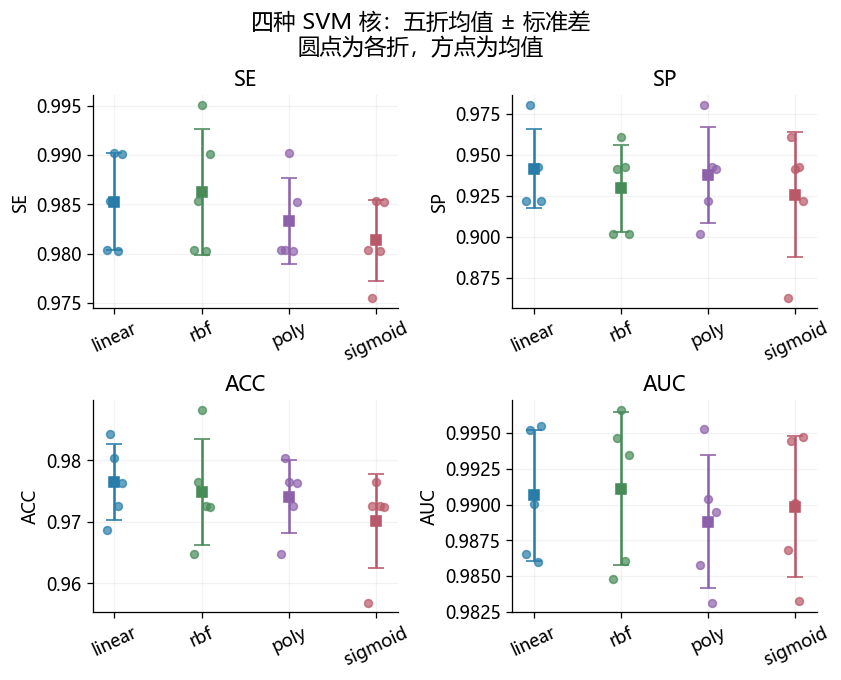

在既定五折划分下，SVM-rbf 的平均 AUC 最高（0.9911），SVM-poly 最低（0.9888）。上述排序反映了当前数据和参数搜索范围下的核函数表现。SE 较高而 SP 较低，表明该核在默认阈值下具有更高的男生识别率，同时伴随较高的女生误判率。AUC 反映分数排序能力，SE 与 SP 则刻画固定阈值下的类别识别表现。

线性核的 ACC 为 97.65%，RBF 核为 97.49%；RBF 的 AUC 较高，但未体现为默认阈值下更高的准确率。Sigmoid 核的 SP 为 92.57%，折间标准差为 3.78%。四种核函数的结果表明，四个特征已提供较强的线性区分信息；非线性模型的性能增益较小，且随评价指标变化。

In [7]:
formatted = pd.DataFrame({"模型": summary.model})
for metric in METRICS:
    formatted[metric] = [f"{mean:.4f} ± {sd:.4f}" for mean, sd in zip(summary[f"{metric}_mean"],summary[f"{metric}_sd"])]
show_table(formatted)
save_table(formatted, "metrics_summary_formatted.csv")
show_table(selection[selection.model.str.startswith("SVM")])
kernel_names = ["SVM-linear", "SVM-rbf", "SVM-poly", "SVM-sigmoid"]
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.8), layout="constrained")
for ax, metric in zip(axes.flat, METRICS):
    for j, name in enumerate(kernel_names):
        values = fold_metrics.loc[fold_metrics.model.eq(name), metric].to_numpy()
        ax.scatter(np.full(5,j)+np.linspace(-0.09,0.09,5), values, color=MODEL_COLORS[name], s=24, alpha=.7)
        ax.errorbar(j, values.mean(), yerr=values.std(ddof=1), marker="s", color=MODEL_COLORS[name], capsize=5, lw=1.6)
    ax.set(xticks=range(4), xticklabels=[n.replace("SVM-","") for n in kernel_names], ylabel=metric, title=metric)
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("四种 SVM 核：五折均值 ± 标准差\n圆点为各折，方点为均值", fontsize=14)
show_figure(fig, "svm_kernel_metrics")
kernel_result = summary[summary.model.isin(kernel_names)].sort_values("AUC_mean", ascending=False)
top_kernel = kernel_result.iloc[0]
bottom_kernel = kernel_result.iloc[-1]
display(Markdown(f"在既定五折划分下，{top_kernel.model} 的平均 AUC 最高（{top_kernel.AUC_mean:.4f}），"
    f"{bottom_kernel.model} 最低（{bottom_kernel.AUC_mean:.4f}）。上述排序反映了当前数据和参数搜索范围下的核函数表现。"
    "SE 较高而 SP 较低，表明该核在默认阈值下具有更高的男生识别率，同时伴随较高的女生误判率。AUC 反映分数排序能力，SE 与 SP 则刻画固定阈值下的类别识别表现。"))
kernel_stats = summary.set_index("model")
display(Markdown(f"线性核的 ACC 为 {kernel_stats.loc['SVM-linear','ACC_mean']:.2%}，"
    f"RBF 核为 {kernel_stats.loc['SVM-rbf','ACC_mean']:.2%}；RBF 的 AUC 较高，但未体现为默认阈值下更高的准确率。"
    f"Sigmoid 核的 SP 为 {kernel_stats.loc['SVM-sigmoid','SP_mean']:.2%}，折间标准差为 {kernel_stats.loc['SVM-sigmoid','SP_sd']:.2%}。"
    "四种核函数的结果表明，四个特征已提供较强的线性区分信息；非线性模型的性能增益较小，且随评价指标变化。"))

### 7. MLP 与 SVM 的配对比较

主比较对象为 **MLP-BP 与 SVM-selected**。后者在每个外层训练集内依据内层验证结果选择核函数，外层测试折仅用于性能评估。
除逐折指标外，展示汇总混淆矩阵和各折 ROC 插值均值。ROC 图例中的 AUC 是**原始每折 AUC 的均值**，不是均值曲线面积，也不是混合不同折分数的 AUC。

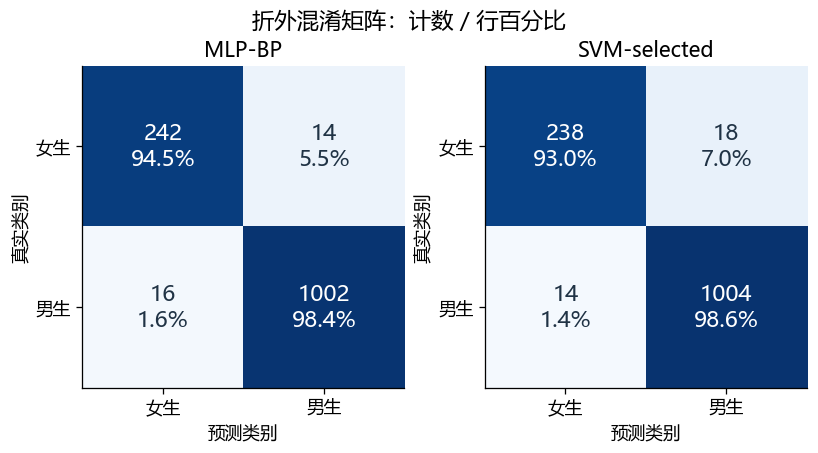

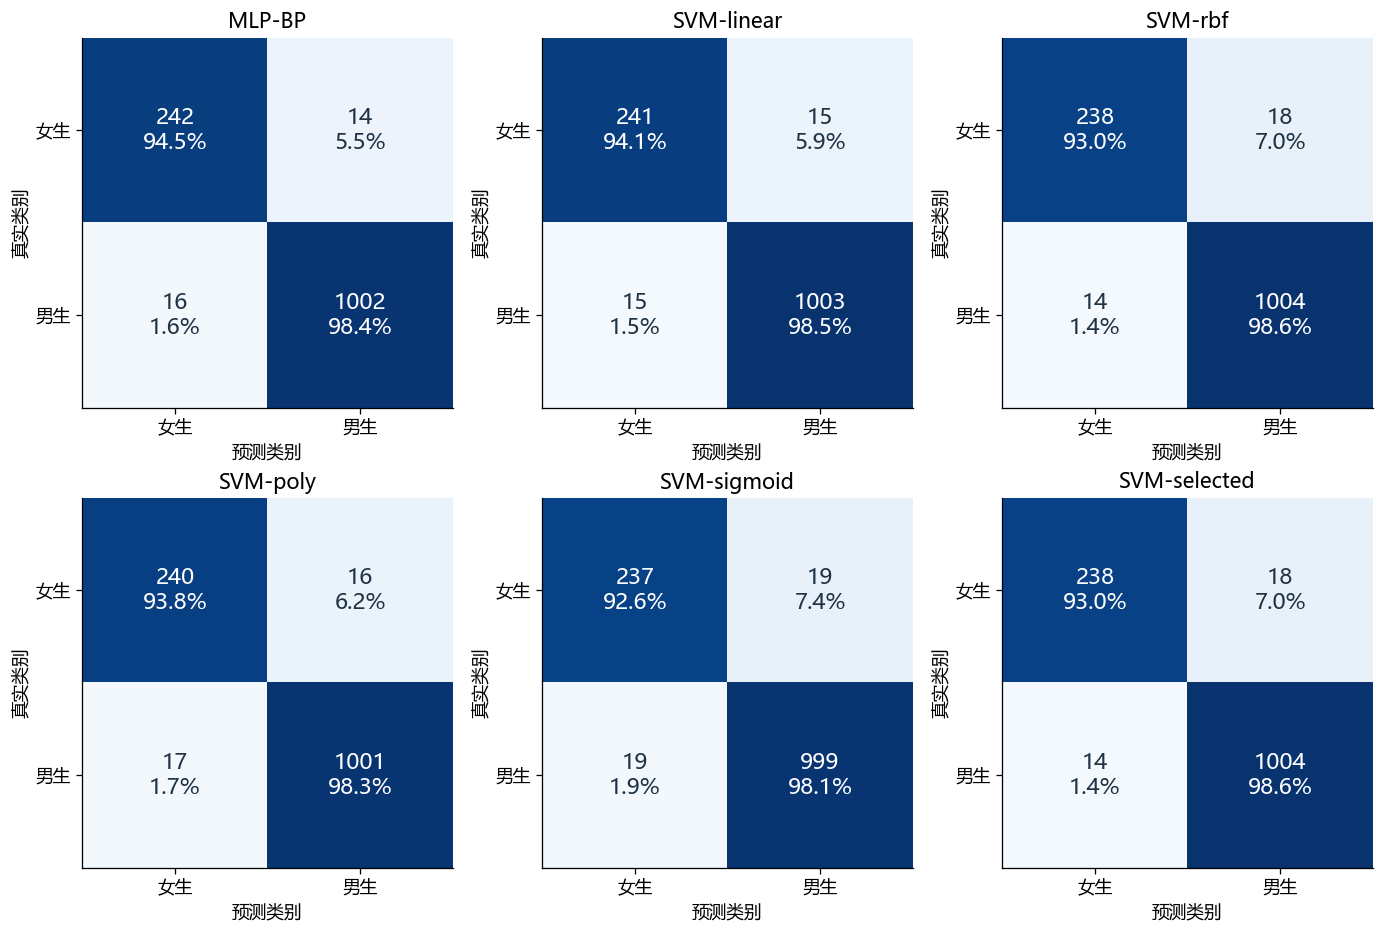

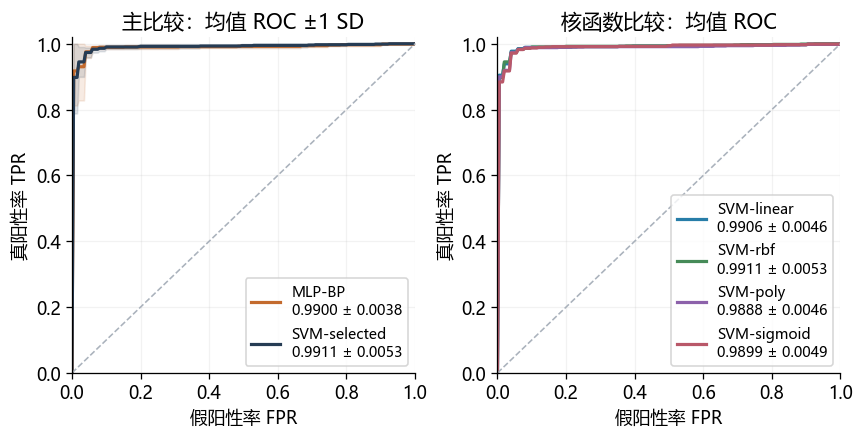

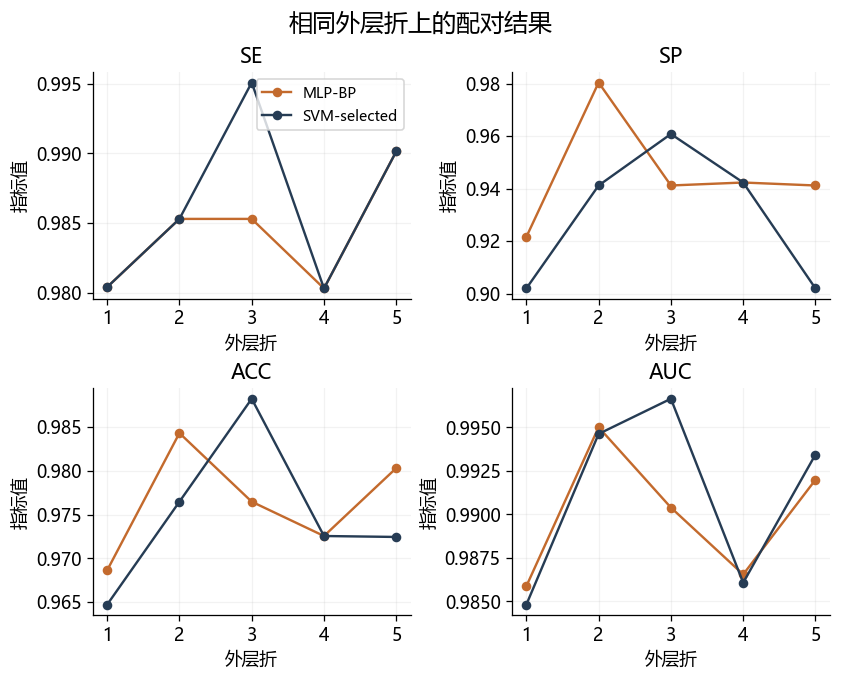

In [8]:
main_names = ["MLP-BP", "SVM-selected"]
fig, axes = plt.subplots(1, 2, figsize=(7, 3.8), layout="constrained")
for ax, name in zip(axes, main_names):
    draw_cm(ax, name)
fig.suptitle("折外混淆矩阵：计数 / 行百分比", fontsize=14)
show_figure(fig, "main_confusion_matrices")
fig, axes = plt.subplots(2, 3, figsize=(12, 8), layout="constrained")
for ax, name in zip(axes.flat, MODEL_NAMES):
    draw_cm(ax, name)
show_figure(fig, "all_confusion_matrices")

grid_fpr = np.linspace(0, 1, 201)
roc_rows = []
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.7), layout="constrained")
for ax, names in zip(axes, [main_names, kernel_names]):
    for name in names:
        curves = []
        for fold, group in oof[oof.model.eq(name)].groupby("fold"):
            fpr, tpr, _ = roc_curve(group.label, group.score)
            interpolated = np.interp(grid_fpr, fpr, tpr)
            interpolated[0], interpolated[-1] = 0, 1
            curves.append(interpolated)
        mean_tpr, sd_tpr = np.mean(curves, axis=0), np.std(curves, axis=0, ddof=1)
        stat = summary.set_index("model").loc[name]
        ax.plot(grid_fpr, mean_tpr, label=f"{name}\n{stat.AUC_mean:.4f} ± {stat.AUC_sd:.4f}", color=MODEL_COLORS[name], lw=2)
        if len(names) == 2:
            ax.fill_between(grid_fpr, np.maximum(0,mean_tpr-sd_tpr), np.minimum(1,mean_tpr+sd_tpr), color=MODEL_COLORS[name], alpha=.13)
        for fpr_value, mean_value, sd_value in zip(grid_fpr,mean_tpr,sd_tpr):
            roc_rows.append({"model": name, "FPR": fpr_value, "TPR_mean": mean_value, "TPR_sd": sd_value})
    ax.plot([0,1],[0,1],"--",color="#AAB2BC",lw=1)
    ax.set(xlabel="假阳性率 FPR", ylabel="真阳性率 TPR", xlim=(0,1), ylim=(0,1.02))
    ax.legend(loc="lower right",fontsize=9)
axes[0].set_title("主比较：均值 ROC ±1 SD")
axes[1].set_title("核函数比较：均值 ROC")
show_figure(fig, "mean_roc_curves")
save_table(pd.DataFrame(roc_rows), "mean_roc.csv")

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.8), layout="constrained")
paired_rows = []
mlp_folds = fold_metrics[fold_metrics.model.eq("MLP-BP")].set_index("fold")
svm_folds = fold_metrics[fold_metrics.model.eq("SVM-selected")].set_index("fold")
for ax, metric in zip(axes.flat, METRICS):
    for name, values in [("MLP-BP", mlp_folds[metric]), ("SVM-selected", svm_folds[metric])]:
        ax.plot(values.index,values,"o-",label=name,color=MODEL_COLORS[name],markersize=5)
    difference = svm_folds[metric] - mlp_folds[metric]
    for fold, value in difference.items():
        paired_rows.append({"fold": fold, "metric": metric, "SVM_minus_MLP": value})
    ax.set(title=metric, xlabel="外层折", xticks=range(1,6), ylabel="指标值")
axes.flat[0].legend(fontsize=9)
fig.suptitle("相同外层折上的配对结果",fontsize=15)
show_figure(fig, "paired_fold_metrics")
paired = pd.DataFrame(paired_rows)
save_table(paired, "paired_metric_differences.csv")

### 8. 误判重叠、特征空间与结果解释

在相同测试样本上比较两种模型的误判重叠，分析共同困难样本及方法间差异。t-SNE 使用全体有效样本进行描述性投影，其缺失值填补与标准化独立于分类模型的交叉验证流程。二维投影用于呈现特征分布与错误样本的位置，不参与性能评价或超参数选择；投影距离仅保留部分四维空间关系，不构成因果解释。

category,female,male,total
两者均对,237,1001,1238
仅 MLP 错,1,3,4
仅 SVM 错,5,1,6
两者均错,13,13,26


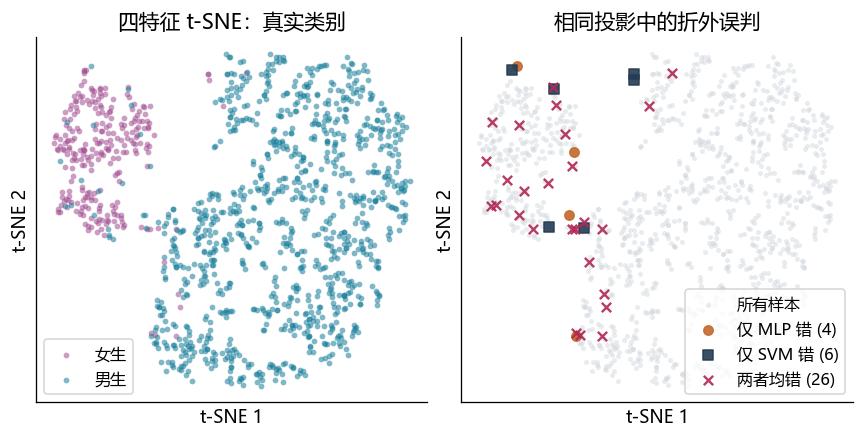

SVM-selected 在五个外层折中的核选择为 **{'rbf': 5}**。与 MLP 相比，SVM-selected 的平均 ACC 变化为 **-0.16 个百分点**，平均 AUC 变化为 **+0.0012**；两者共同误判 **26** 条，仅 MLP 误判 **4** 条，仅 SVM 误判 **6** 条。整体指标、类别误判分布和错误重叠表明，两种方法的总体性能接近，但对两类样本的识别存在差异。由于各折训练集存在重叠，折间标准差用于描述本次划分的结果离散程度，不作为统计显著性的判据。

配对折结果显示，SVM-selected 的 AUC 仅在 **2/5** 折高于 MLP。在默认阈值下，SVM 比 MLP 少误判 2 名男生，同时多误判 4 名女生。AUC 的小幅优势反映分数排序的改善，与两类样本在固定阈值下的识别改善并不等价。在至少一种模型误判的样本中，72.2% 被两者共同误判，表明两种方法具有较高的误判样本重叠率。

在共同误判样本中，女生的平均身高为 167.9 cm、鞋码为 39.5，男生的平均身高为 162.6 cm、鞋码为 37.4。共同误判组的特征与各自类别主体分布存在偏离，与 t-SNE 中异类邻域内出现错误点的观察相符。上述组间均值差异属于样本分布的描述性结果，不构成个体标签判定依据。

In [9]:
wide_predictions = oof.pivot(index="row_id", columns="model", values="prediction").reindex(clean.row_id)
mlp_error = wide_predictions["MLP-BP"].to_numpy() != y
svm_error = wide_predictions["SVM-selected"].to_numpy() != y
error_category = np.select([mlp_error & svm_error, mlp_error & ~svm_error, ~mlp_error & svm_error],
                           ["两者均错", "仅 MLP 错", "仅 SVM 错"], default="两者均对")
error_table = pd.crosstab(pd.Series(error_category,name="category"),pd.Series(y,name="label")).reindex(
    ["两者均对","仅 MLP 错","仅 SVM 错","两者均错"],fill_value=0).reset_index()
error_table.columns = ["category","female","male"]
error_table["total"] = error_table.female + error_table.male
show_table(error_table,0)
save_table(error_table,"error_overlap.csv")
error_details = clean.copy()
error_details["MLP_prediction"] = wide_predictions["MLP-BP"].to_numpy()
error_details["SVM_prediction"] = wide_predictions["SVM-selected"].to_numpy()
error_details["category"] = error_category
error_details["fold"] = fold_for_sample
save_table(error_details[mlp_error | svm_error],"misclassified_samples.csv")
save_table(error_details.groupby(["category","label"])[FEATURES].mean().reset_index(),"error_group_feature_means.csv")

descriptive_X = make_preprocessor().fit_transform(X)
embedding = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", max_iter=1000,
                 random_state=SEED).fit_transform(descriptive_X)
embedding_table = pd.DataFrame({"row_id": clean.row_id, "label": y, "tSNE1": embedding[:,0],
                                "tSNE2": embedding[:,1], "error_category": error_category})
save_table(embedding_table,"tsne_coordinates.csv")
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.7), layout="constrained")
for label in [0,1]:
    mask = y == label
    axes[0].scatter(embedding[mask,0],embedding[mask,1],s=13,alpha=.55,color=CLASS_COLORS[label],label=CLASS_NAMES[label],linewidths=0)
axes[0].set_title("四特征 t-SNE：真实类别")
axes[1].scatter(embedding[:,0],embedding[:,1],s=10,c="#CFD5DC",alpha=.45,linewidths=0,label="所有样本")
for category, color, marker in [("仅 MLP 错","#C36A2D","o"),("仅 SVM 错","#263C54","s"),("两者均错","#B12954","x")]:
    mask = error_category == category
    axes[1].scatter(embedding[mask,0],embedding[mask,1],s=34,c=color,marker=marker,alpha=.9,label=f"{category} ({mask.sum()})")
axes[1].set_title("相同投影中的折外误判")
for ax in axes:
    ax.set(xlabel="t-SNE 1",ylabel="t-SNE 2",xticks=[],yticks=[])
axes[0].legend(fontsize=10, loc="lower left")
axes[1].legend(fontsize=10, loc="lower right")
show_figure(fig,"tsne_errors")

main_summary = summary.set_index("model").loc[main_names]
diff = main_summary.loc["SVM-selected"] - main_summary.loc["MLP-BP"]
count_selected = selection[selection.model.eq("SVM-selected")].parameters.map(lambda s:json.loads(s)["kernel"]).value_counts().to_dict()
analysis_evidence = {"main_models": main_names, "svm_selected_kernel_counts": count_selected,
    "SVM_minus_MLP_mean": {m:float(diff[f"{m}_mean"]) for m in METRICS},
    "paired_SVM_wins": {m:int((svm_folds[m]>mlp_folds[m]).sum()) for m in METRICS},
    "paired_ties": {m:int((svm_folds[m]==mlp_folds[m]).sum()) for m in METRICS},
    "both_wrong": int((mlp_error&svm_error).sum()), "only_MLP_wrong": int((mlp_error&~svm_error).sum()),
    "only_SVM_wrong": int((~mlp_error&svm_error).sum()), "both_correct": int((~mlp_error&~svm_error).sum()),
    "confusion_matrices": {name:cm_for(name).tolist() for name in MODEL_NAMES},
    "gradient_max_absolute_error": float(gradient_check.absolute_error.max()),
    "gradient_max_relative_error": float(gradient_check.relative_error.max())}
(OUT/"analysis_evidence.json").write_text(json.dumps(analysis_evidence,ensure_ascii=False,indent=2),encoding="utf-8")
display(Markdown(f"SVM-selected 在五个外层折中的核选择为 **{count_selected}**。与 MLP 相比，SVM-selected 的平均 ACC 变化为 **{diff.ACC_mean*100:+.2f} 个百分点**，"
    f"平均 AUC 变化为 **{diff.AUC_mean:+.4f}**；两者共同误判 **{(mlp_error&svm_error).sum()}** 条，"
    f"仅 MLP 误判 **{(mlp_error&~svm_error).sum()}** 条，仅 SVM 误判 **{(~mlp_error&svm_error).sum()}** 条。"
    "整体指标、类别误判分布和错误重叠表明，两种方法的总体性能接近，但对两类样本的识别存在差异。"
    "由于各折训练集存在重叠，折间标准差用于描述本次划分的结果离散程度，不作为统计显著性的判据。"))
display(Markdown(f"配对折结果显示，SVM-selected 的 AUC 仅在 **{int((svm_folds.AUC>mlp_folds.AUC).sum())}/5** 折高于 MLP。"
    f"在默认阈值下，SVM 比 MLP 少误判 {(mlp_cm[1,0]-cm_for('SVM-selected')[1,0])} 名男生，同时多误判 {(cm_for('SVM-selected')[0,1]-mlp_cm[0,1])} 名女生。"
    "AUC 的小幅优势反映分数排序的改善，与两类样本在固定阈值下的识别改善并不等价。"
    f"在至少一种模型误判的样本中，{(mlp_error&svm_error).sum()/(mlp_error|svm_error).sum():.1%} 被两者共同误判，表明两种方法具有较高的误判样本重叠率。"))
group_means = error_details.groupby(["category","label"])[FEATURES].mean()
female_difficult = group_means.loc[("两者均错",0)]
male_difficult = group_means.loc[("两者均错",1)]
display(Markdown(f"在共同误判样本中，女生的平均身高为 {female_difficult.iloc[0]:.1f} cm、鞋码为 {female_difficult.iloc[2]:.1f}，"
    f"男生的平均身高为 {male_difficult.iloc[0]:.1f} cm、鞋码为 {male_difficult.iloc[2]:.1f}。"
    "共同误判组的特征与各自类别主体分布存在偏离，与 t-SNE 中异类邻域内出现错误点的观察相符。"
    "上述组间均值差异属于样本分布的描述性结果，不构成个体标签判定依据。"))

### 9. 实验小结与复现检查

本实验固定了四个输入特征和 3 个隐层节点，通过中心差分核对手写 BP，再用相同嵌套五折评估 MLP 与 SVM。外层结果显示，两者性能接近：MLP 在默认阈值下的 ACC 和 SP 略高，内层选核 SVM 的平均 AUC 略高，但仅在两折中超过 MLP；多数误判样本重合。结合线性核的表现可知，增加非线性表达能力在本次数据上带来的性能收益有限。

实验结果对应当前课程数据、既定参数搜索范围及一次分层五折划分。数据存在类别不平衡和录入误差，不同编号对应个体的独立性尚缺乏进一步核实信息。跨学校人群的适用性仍需独立数据验证。t-SNE 用于描述性分析，训练损失用于评价优化过程。

从项目根目录使用 `.venv` 内核执行全部单元即可复现。`protocol.json` 记录数据 SHA-256、库版本、清洗规则、网格和随机种子；`fold_assignments.csv`、`fold_metrics.csv` 与 `oof_predictions.csv` 可分别追溯划分、逐折指标和每个样本的折外判别。

方法与 API 参考：[scikit-learn 1.7 SVM 用户指南](https://scikit-learn.org/1.7/modules/svm.html)、[交叉验证与嵌套选择](https://scikit-learn.org/1.7/auto_examples/model_selection/plot_nested_cross_validation_iris.html)、[roc_auc_score](https://scikit-learn.org/1.7/modules/generated/sklearn.metrics.roc_auc_score.html)、[t-SNE](https://scikit-learn.org/1.7/modules/generated/sklearn.manifold.TSNE.html)、[LIBSVM FAQ：核与数值行为](https://www.csie.ntu.edu.tw/~cjlin/libsvm/faq.html)。

In [10]:
assert len(fold_metrics) == 5*len(MODEL_NAMES)
assert len(oof) == len(clean)*len(MODEL_NAMES)
assert not fold_metrics[METRICS].isna().any().any()
assert ((fold_metrics[METRICS] >= 0) & (fold_metrics[METRICS] <= 1)).all().all()
assert int((fold_metrics.model=="MLP-BP").sum()) == 5
for name in MODEL_NAMES:
    assert int(cm_for(name).sum()) == len(clean)
    assert np.array_equal(cm_for(name).sum(axis=1), np.bincount(y,minlength=2))
for fold in range(1,6):
    model = outer_models[fold]["models"]["MLP-BP"]
    assert sum(p.size for p in model.params.values()) == 19
    assert model.params["W1"].shape == (4,3) and model.params["W2"].shape == (3,1)
output_manifest = {"tables": sorted(p.name for p in OUT.glob("*.csv")),
                   "figures": sorted(p.name for p in FIG.iterdir()),
                   "checks": {"gradient_check": "passed", "five_folds_shared": "passed",
                       "one_OOF_prediction_per_model_sample": "passed", "architecture_4_3_1": "passed",
                       "finite_metrics_in_0_1": "passed"}}
(OUT/"manifest.json").write_text(json.dumps(output_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("完整性检查全部通过。结果目录：", OUT.resolve())
show_table(formatted)

完整性检查全部通过。结果目录： D:\Projects\Playground\PatternRecognitionHomework\results\homework2


模型,SE,SP,ACC,AUC
MLP-BP,0.9843 ± 0.0041,0.9453 ± 0.0214,0.9765 ± 0.0062,0.9900 ± 0.0038
SVM-linear,0.9853 ± 0.0049,0.9414 ± 0.0240,0.9765 ± 0.0062,0.9906 ± 0.0046
SVM-rbf,0.9862 ± 0.0064,0.9296 ± 0.0264,0.9749 ± 0.0086,0.9911 ± 0.0053
SVM-poly,0.9833 ± 0.0044,0.9375 ± 0.0291,0.9741 ± 0.0059,0.9888 ± 0.0046
SVM-sigmoid,0.9813 ± 0.0041,0.9257 ± 0.0378,0.9702 ± 0.0076,0.9899 ± 0.0049
SVM-selected,0.9862 ± 0.0064,0.9296 ± 0.0264,0.9749 ± 0.0086,0.9911 ± 0.0053
